In [1]:
import os

os.makedirs("/root/.kaggle", exist_ok=True)

In [ ]:
token = "KGAT_c8671e335a1b54c0ffaa6219d238d714"

with open("/root/.kaggle/access_token", "w") as f:
    f.write(token)

In [ ]:
!chmod 600 /root/.kaggle/access_token

In [ ]:
!kaggle competitions download -c titanic

100% 34.1k/34.1k [00:00<00:00, 2.53MB/s]



In [ ]:
!unzip -o titanic.zip

Archive:  titanic.zip
  inflating: gender_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


In [ ]:
!ls


gender_submission.csv  sample_data  test.csv  titanic.zip  train.csv


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv("train.csv")

In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.tail()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [ ]:
df.shape


(891, 12)

In [ ]:
df.columns


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe(include="all")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [ ]:
df.duplicated().sum()


np.int64(0)

In [ ]:
df["Sex"].unique()


array(['male', 'female'], dtype=object)

In [ ]:
df["Embarked"].unique()

array(['S', 'C', 'Q', nan], dtype=object)

In [ ]:
df.nunique()

,0
PassengerId,891
Survived,2
Pclass,3
Name,891
Sex,2
Age,88
SibSp,7
Parch,7
Ticket,681
Fare,248


In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
missing_percentage = (df.isnull().sum()/len(df))*100
print(missing_percentage)

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


## Missing Values Imputation

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

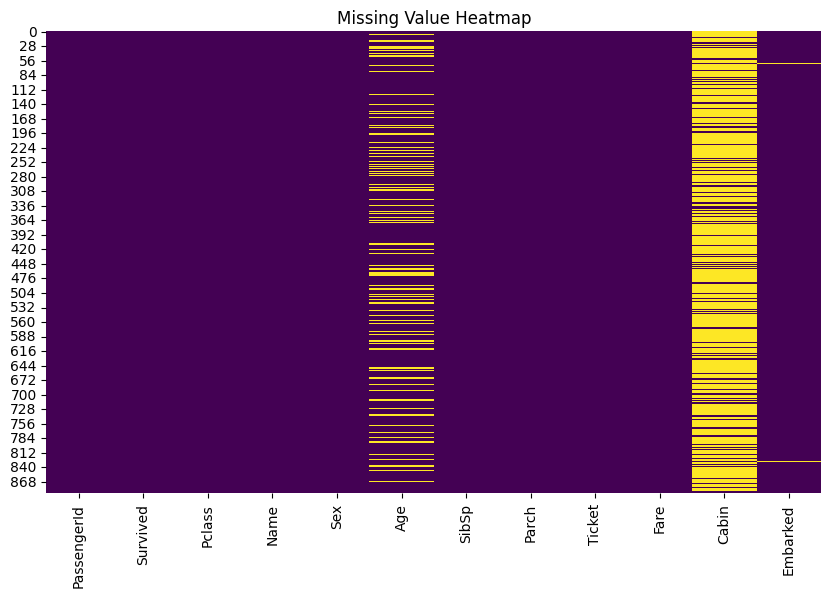

In [ ]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.isnull(),
    cmap="viridis",
    cbar=False
)

plt.title("Missing Value Heatmap")
plt.show()

In [ ]:
df["Age"].median()

28.0

In [ ]:
df["Age"] = df["Age"].fillna(
    df["Age"].median()
)

In [ ]:
df["Age"].isnull().sum()

np.int64(0)

### Imputing Missing Values for Embarked

In [ ]:
df["Embarked"].isnull().sum()


np.int64(2)

In [ ]:
df["Embarked"].mode()

,Embarked
0,S


In [ ]:
df["Embarked"] = df["Embarked"].fillna(
    df["Embarked"].mode()[0]
)

In [ ]:
df["Embarked"].isnull().sum()

np.int64(0)

### Handling Missing Values for Cabin

In [ ]:
df["Cabin"].isnull().sum()

np.int64(687)

In [ ]:
df["Cabin_Deck"] = df["Cabin"].str[0]

In [ ]:
df["Cabin_Deck"].value_counts()

,count
Cabin_Deck,
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


In [ ]:
df.drop("Cabin", axis=1, inplace=True)

In [ ]:
df["Cabin_Deck"] = df["Cabin_Deck"].fillna(
    "Unknown"
)

In [ ]:
print(df["Cabin_Deck"].head())

0    Unknown
1          C
2    Unknown
3          C
4    Unknown
Name: Cabin_Deck, dtype: object


In [ ]:
df.isnull().sum()


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## Renaming Columns

In [ ]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked', 'Cabin_Deck'],
      dtype='object')

In [ ]:
df.rename(
    columns={
        "PassengerId": "passenger_id",
        "SibSp": "siblings_spouses",
        "Parch": "parents_children",
        "Cabin_Deck": "cabin_deck"
    },
    inplace=True
)

In [ ]:
df.head()

,passenger_id,Survived,Pclass,Name,Sex,Age,siblings_spouses,parents_children,Ticket,Fare,Embarked,cabin_deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Unknown
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,C
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Unknown


In [ ]:
df.duplicated().sum()

np.int64(0)

## Dropping Duplicates

In [ ]:
df.drop_duplicates(inplace=True)

OUTLIERS DETECTION

In [ ]:
df.select_dtypes(include=['int64','float64']).columns

Index(['passenger_id', 'Survived', 'Pclass', 'Age', 'siblings_spouses',
       'parents_children', 'Fare'],
      dtype='object')

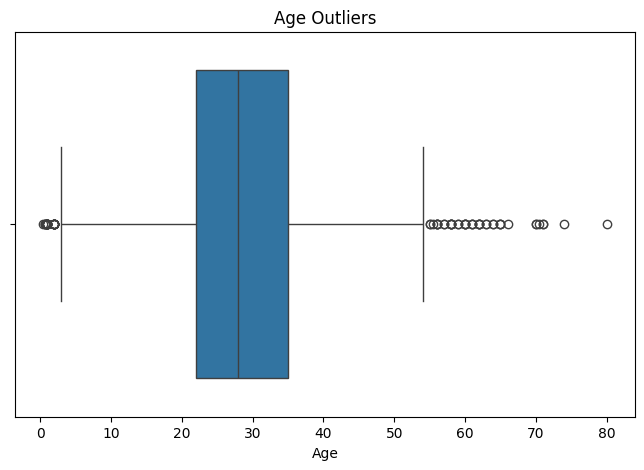

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["Age"]
)

plt.title("Age Outliers")
plt.show()

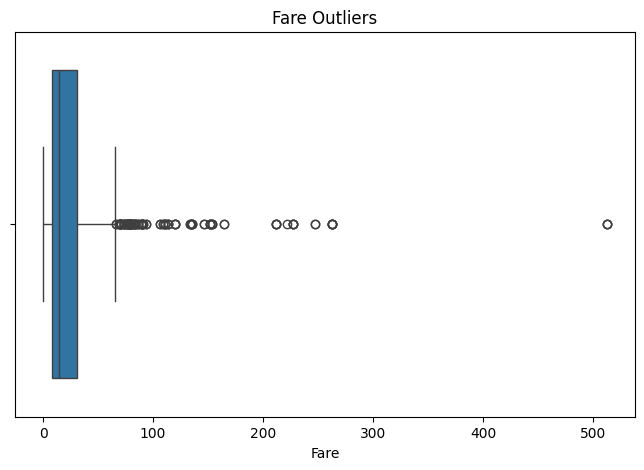

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["Fare"]
)

plt.title("Fare Outliers")
plt.show()

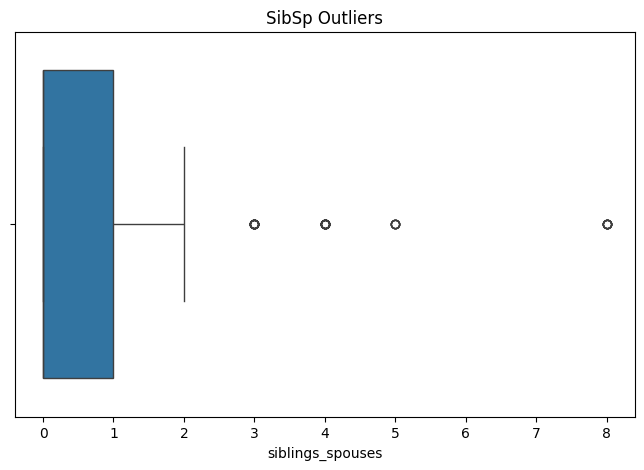

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["siblings_spouses"]
)

plt.title("SibSp Outliers")
plt.show()

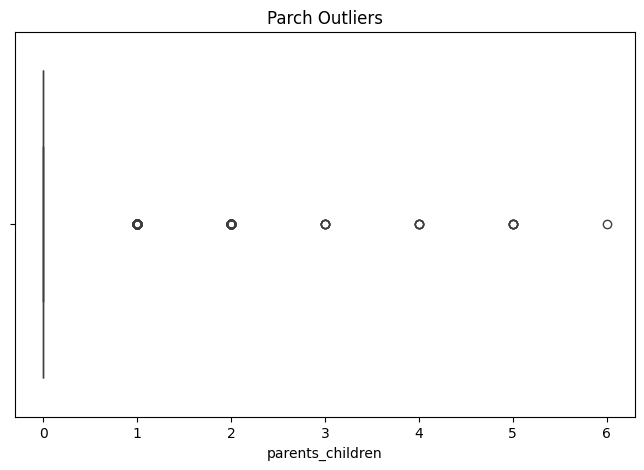

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["parents_children"]
)

plt.title("Parch Outliers")
plt.show()

## Data Type Conversion

In [ ]:
def detect_outliers(column):

    Q1 = df[column].quantile(0.25)

    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR

    upper_limit = Q3 + 1.5 * IQR

    print(f"Column: {column}")
    print(f"  Lower Limit: {lower_limit}")
    print(f"  Upper Limit: {upper_limit}")

    outliers = \
        df[
            (df[column] < lower_limit) |
            (df[column] > upper_limit)
        ]

    return outliers

In [ ]:
age_outliers = detect_outliers("Age")

age_outliers.shape


(66, 24)

In [ ]:
age_outliers[["Age"]]

,Age
7,0.019854
11,0.723549
15,0.685851
16,0.019854
33,0.824076
...,...
827,0.007288
829,0.773813
831,0.005152
851,0.924604


For People in ages belonging to outlier ranges we donot remove them or cap them instead we keep them as they have age dependent survival probability

In [ ]:
fare_outliers = detect_outliers("Fare")

fare_outliers.shape

(116, 12)

In [ ]:
fare_outliers[["Fare","Pclass"]]

,Fare,Pclass
1,71.2833,1
27,263.0000,1
31,146.5208,1
34,82.1708,1
52,76.7292,1
...,...,...
846,69.5500,3
849,89.1042,1
856,164.8667,1
863,69.5500,3


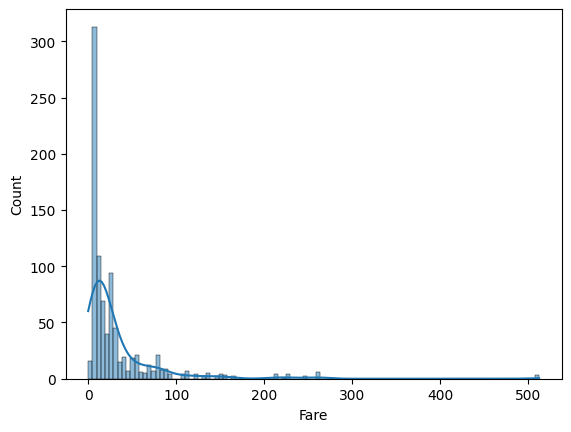

In [ ]:
sns.histplot(
    df["Fare"],
    kde=True
)

plt.show()

In [ ]:
df["Fare_log"] = np.log1p(df["Fare"])

In [ ]:
df[["Fare","Fare_log"]].head()

,Fare,Fare_log
0,7.2500,2.110213
1,71.2833,4.280593
2,7.9250,2.188856
3,53.1000,3.990834
4,8.0500,2.202765


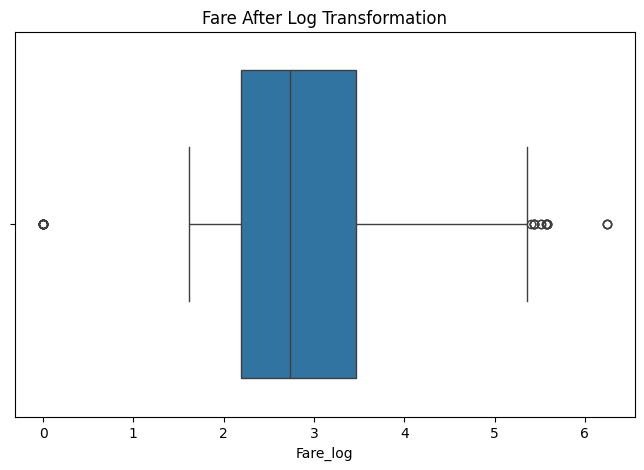

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["Fare_log"]
)

plt.title("Fare After Log Transformation")

plt.show()

In [ ]:
siblings_spouses_outliers = detect_outliers("siblings_spouses")

siblings_spouses_outliers.shape

(46, 13)

In [ ]:
siblings_spouses_outliers[["siblings_spouses"]].head()

,siblings_spouses
7,3
16,4
24,3
27,3
50,4


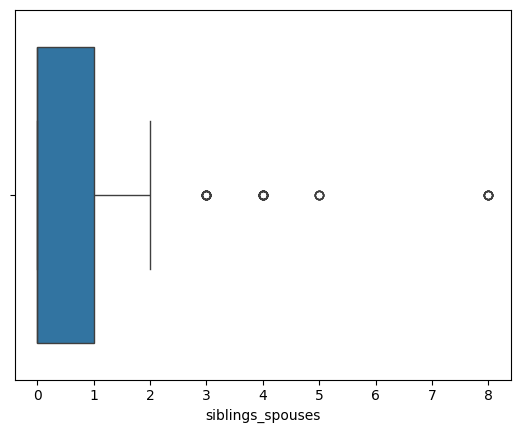

In [ ]:
sns.boxplot(
    x=df["siblings_spouses"]
)


plt.show()

keep the original counts as they denote actual family size

In [ ]:
parch_outliers = detect_outliers("parents_children")

parch_outliers[["parents_children"]]

,parents_children
7,1
8,2
10,1
13,5
16,1
...,...
871,1
879,1
880,1
885,5


## Data Type Conversion

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   passenger_id      891 non-null    int64  
 1   Survived          891 non-null    int64  
 2   Pclass            891 non-null    int64  
 3   Name              891 non-null    object 
 4   Sex               891 non-null    object 
 5   Age               891 non-null    float64
 6   siblings_spouses  891 non-null    int64  
 7   parents_children  891 non-null    int64  
 8   Ticket            891 non-null    object 
 9   Fare              891 non-null    float64
 10  Embarked          891 non-null    object 
 11  cabin_deck        891 non-null    object 
 12  Fare_log          891 non-null    float64
dtypes: float64(3), int64(5), object(5)
memory usage: 90.6+ KB


In [ ]:
df["Pclass"] = df["Pclass"].astype("category")

In [ ]:
df["Sex"] = df["Sex"].astype("category")

In [ ]:
df["Embarked"] = df["Embarked"].astype("category")

In [ ]:
df["cabin_deck"] = df["cabin_deck"].astype("category")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   passenger_id      891 non-null    int64   
 1   Survived          891 non-null    int64   
 2   Pclass            891 non-null    category
 3   Name              891 non-null    object  
 4   Sex               891 non-null    category
 5   Age               891 non-null    float64 
 6   siblings_spouses  891 non-null    int64   
 7   parents_children  891 non-null    int64   
 8   Ticket            891 non-null    object  
 9   Fare              891 non-null    float64 
 10  Embarked          891 non-null    category
 11  cabin_deck        891 non-null    category
 12  Fare_log          891 non-null    float64 
dtypes: category(4), float64(3), int64(4), object(2)
memory usage: 67.0+ KB


## Dropping Original Fare Column

In [ ]:
df.drop("Fare", axis=1, inplace=True)

In [ ]:
print(df.dtypes)

passenger_id           int64
Survived               int64
Pclass              category
Name                  object
Sex                 category
Age                  float64
siblings_spouses       int64
parents_children       int64
Ticket                object
Embarked            category
cabin_deck          category
Fare_log             float64
dtype: object


## Encoding Categorical Features

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["Sex"] = le.fit_transform(df["Sex"])

In [ ]:
print(df["Sex"].unique())
print(df["Sex"].value_counts())

[1 0]
Sex
1    577
0    314
Name: count, dtype: int64


### One-Hot Encoding for Pclass, Embarked, and Cabin_Deck

In [ ]:
df = pd.get_dummies(
    df,
    columns=["Pclass", "Embarked", "cabin_deck"],
    drop_first=False
)

In [ ]:
print(df.dtypes)

passenger_id            int64
Survived                int64
Name                   object
Sex                     int64
Age                   float64
siblings_spouses        int64
parents_children        int64
Ticket                 object
Fare_log              float64
Pclass_1                 bool
Pclass_2                 bool
Pclass_3                 bool
Embarked_C               bool
Embarked_Q               bool
Embarked_S               bool
cabin_deck_A             bool
cabin_deck_B             bool
cabin_deck_C             bool
cabin_deck_D             bool
cabin_deck_E             bool
cabin_deck_F             bool
cabin_deck_G             bool
cabin_deck_T             bool
cabin_deck_Unknown       bool
dtype: object


## Scaling Numerical Features

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

columns_to_normalize = [
    "Age",
    "Fare_log",
    "siblings_spouses",
    "parents_children"
]

df[columns_to_normalize] = scaler.fit_transform(df[columns_to_normalize])

In [ ]:
print(df[columns_to_normalize].describe())

              Age    Fare_log  siblings_spouses  parents_children
count  891.000000  891.000000        891.000000        891.000000
mean     0.363679    0.474649          0.065376          0.063599
std      0.163605    0.155273          0.137843          0.134343
min      0.000000    0.000000          0.000000          0.000000
25%      0.271174    0.350464          0.000000          0.000000
50%      0.346569    0.438698          0.000000          0.000000
75%      0.434531    0.555325          0.125000          0.000000
max      1.000000    1.000000          1.000000          1.000000


In [ ]:
print(df.head())
print(df.info())
print(df.describe())

   passenger_id  Survived                                               Name  \
0             1         0                            Braund, Mr. Owen Harris   
1             2         1  Cumings, Mrs. John Bradley (Florence Briggs Th...   
2             3         1                             Heikkinen, Miss. Laina   
3             4         1       Futrelle, Mrs. Jacques Heath (Lily May Peel)   
4             5         0                           Allen, Mr. William Henry   

   Sex       Age  siblings_spouses  parents_children            Ticket  \
0    1  0.271174             0.125               0.0         A/5 21171   
1    0  0.472229             0.125               0.0          PC 17599   
2    0  0.321438             0.000               0.0  STON/O2. 3101282   
3    0  0.434531             0.125               0.0            113803   
4    1  0.434531             0.000               0.0            373450   

   Fare_log  Pclass_1  ...  Embarked_S  cabin_deck_A  cabin_deck_B  \
0  0

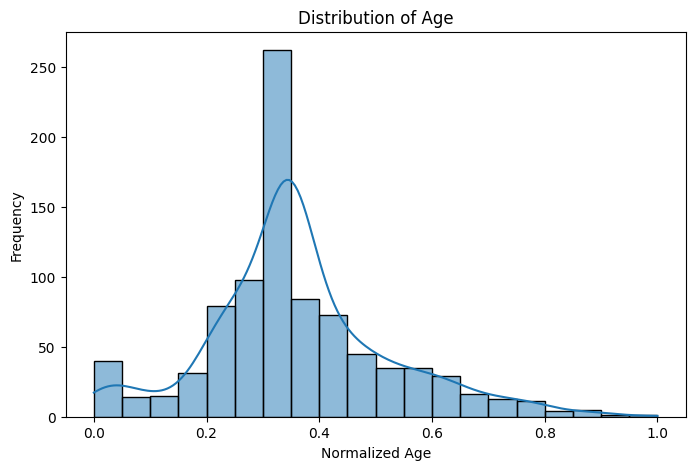

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(df["Age"], bins=20, kde=True)

plt.title("Distribution of Age")
plt.xlabel("Normalized Age")
plt.ylabel("Frequency")
plt.show()

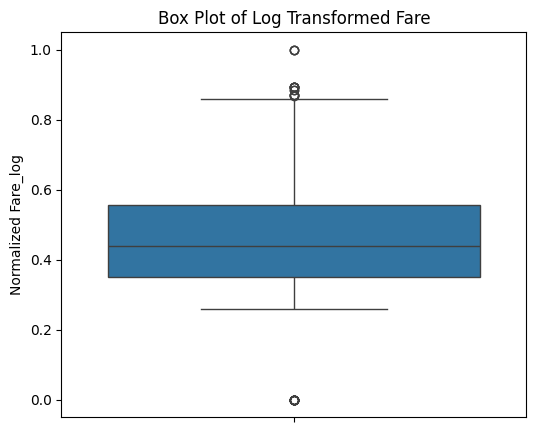

In [ ]:
plt.figure(figsize=(6,5))
sns.boxplot(y=df["Fare_log"])

plt.title("Box Plot of Log Transformed Fare")
plt.ylabel("Normalized Fare_log")
plt.show()

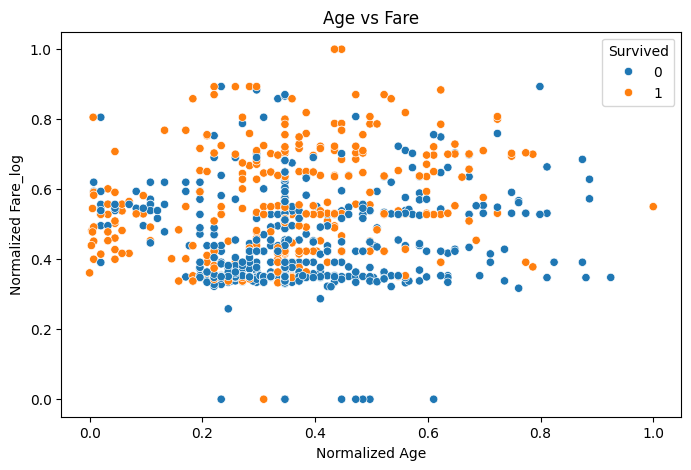

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x=df["Age"],
    y=df["Fare_log"],
    hue=df["Survived"]
)

plt.title("Age vs Fare")
plt.xlabel("Normalized Age")
plt.ylabel("Normalized Fare_log")
plt.show()